# Дипломски рад

**Аутор:** Тијана Ђоковић

Анализа фактора који се односе на опредељење за СТЕМ смер у средњој школи (упитник, подаци у `STEM.xlsx`). У наставку: припрема података, дефиниција циљне променљиве, описна анализа и основни статистички тестови.

# 1. Припрема података

## 1.1. Учитавање и преглед скупа података

Учитавамо одговоре из Excel фајла (`STEM.xlsx` — без измене из кода), користимо **pandas** за табеларне податке, **seaborn/matplotlib** за графике и **scipy.stats** за тестове.

Пре моделовања (ако се додаје касније) вредно је проверити недостајуће вредности, типове колона и да ли текстуални одговори имају неочекиване варијанте (размак, различит писмо).

**Напомена о називима колона:** Након учитавања, у овом notebook-у скраћујемо само називе колона за *најчешћу оцену по предмету*, *занимљивост*, *тежину* и *корисност* предмета (исти текст као у упитнику, скраћен за прегледност). Изворни фајл `STEM.xlsx` се **не мења** — преименовање важи само за `DataFrame` у сећији испод.

In [1]:
import re

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import ttest_ind, chi2_contingency

sns.set_style("whitegrid")


In [2]:
df = pd.read_excel("STEM.xlsx")


def _rename_subject_question_columns(columns):
    """Скраћени називи колона за предмете (само у овом DataFrame-у; Excel остаје непромењен)."""
    rename = {}
    pat_grade = re.compile(
        r"^Најчешћа оцена из наведених предмета у основној школи ми је била: (\[.+\])$"
    )
    pat_zan = re.compile(
        r"^Колико ти је поједини предмет био занимљив у основној школи\?\s+(\[.+\])$"
    )
    pat_tez = re.compile(
        r"^Колико ти је поједини предмет био тежак у основној школи\?\s+(\[.+\])$"
    )
    pat_kor = re.compile(
        r"^Колико ти је поједини предмет био користан у основној школи\?\s+(\[.+\])$"
    )
    for col in columns:
        if not isinstance(col, str):
            continue
        m = pat_grade.match(col)
        if m:
            rename[col] = f"Најчешћа оцена {m.group(1)}"
            continue
        m = pat_zan.match(col)
        if m:
            rename[col] = f"Занимљив {m.group(1)}"
            continue
        m = pat_tez.match(col)
        if m:
            rename[col] = f"Тежак {m.group(1)}"
            continue
        m = pat_kor.match(col)
        if m:
            rename[col] = f"Корисан {m.group(1)}"
            continue
    return rename


df.rename(columns=_rename_subject_question_columns(df.columns), inplace=True)
df.head()

,Timestamp,Пол:,Година рођења:,Похађам средњу школу:,Смер:,Разред:,Одрастао/ла сам у:,Основну школу сам завршио/ла у:,Занимање твоје мајке:,Стручна спрема твоје мајке:,...,Процени који од фактора је имао колико утицаја на твоју одлуку за упис и похађање изабраног смера. [Вршњаци],Процени који од фактора је имао колико утицаја на твоју одлуку за упис и похађање изабраног смера. [Наставник],"Процени који од фактора је имао колико утицаја на твоју одлуку за упис и похађање изабраног смера. [Медији (телевизија, друштвене мреже, интернет, блогови итд)]",Процени који од фактора је имао колико утицаја на твоју одлуку за упис и похађање изабраног смера. [Склоност ка одређеној групи предмета],Процени који од фактора је имао колико утицаја на твоју одлуку за упис и похађање изабраног смера. [Добра проходност на факултет који желим да студирам по завршетку средње школе],Процени који од фактора је имао колико утицаја на твоју одлуку за упис и похађање изабраног смера. [Интересовање за занимање којим желим да се бавим у будућности],Процени колико је ко од запослених у основној школи водио са тобом разговор и саветовао те око одабира средње школе и професионалне оријентације. [Школски психолог/педагог],Процени колико је ко од запослених у основној школи водио са тобом разговор и саветовао те око одабира средње школе и професионалне оријентације. [Разредни старешина],Процени колико је ко од запослених у основној школи водио са тобом разговор и саветовао те око одабира средње школе и професионалне оријентације. [Предметни наставник],Процени колико је ко од запослених у основној школи водио са тобом разговор и саветовао те око одабира средње школе и професионалне оријентације. [Неко друго стручно лице]
0,2023-11-28 21:50:20.078,мушки,2007,„Јован Јовановић Змај“ Нови Сад,специјализовано одељење за ученике са посебним...,2.0,већем граду,већем граду,preduzetnica,завршен факултет,...,1 - нимало,2 - мало,3 - средње,5 - изразито,5 - изразито,5 - изразито,1 - нимало,1 - нимало,1 - нимало,1 - нимало
1,2023-11-28 21:52:10.331,женски,2005,„Јован Јовановић Змај“ Нови Сад,природно-математички,4.0,варошици,варошици,Radnik,завршена виша школа,...,1 - нимало,4 - доста,4 - доста,5 - изразито,5 - изразито,4 - доста,1 - нимало,2 - мало,4 - доста,1 - нимало
2,2023-11-28 21:52:16.136,женски,2005,„Јован Јовановић Змај“ Нови Сад,специјализовано одељење за ученике са посебним...,4.0,већем граду,већем граду,Lekar,завршен факултет,...,1 - нимало,1 - нимало,1 - нимало,2 - мало,4 - доста,1 - нимало,1 - нимало,1 - нимало,1 - нимало,1 - нимало
3,2023-11-28 21:52:17.193,женски,2007,„Јован Јовановић Змај“ Нови Сад,билингвално одељење (одељење у коме се део нас...,3.0,већем граду,већем граду,Diplomirani ekonomista,завршен факултет,...,3 - средње,4 - доста,2 - мало,5 - изразито,3 - средње,1 - нимало,5 - изразито,2 - мало,3 - средње,1 - нимало
4,2023-11-28 21:52:41.167,женски,2008,„Јован Јовановић Змај“ Нови Сад,природно-математички,1.0,селу,селу,Ekonomista,завршен факултет,...,1 - нимало,3 - средње,1 - нимало,3 - средње,4 - доста,4 - доста,4 - доста,5 - изразито,4 - доста,4 - доста


## 1.2. Основне информације о скупу података

`info()` приказује типове и недостајуће вредности по колони; `describe()` сажетак за нумеричке колоне; `shape` број редова и колона.

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1044 entries, 0 to 1043
Columns: 105 entries, Timestamp to Процени колико је ко од запослених у основној школи водио са тобом разговор и саветовао те око одабира средње школе и професионалне оријентације. [Неко друго стручно лице]
dtypes: datetime64[ns](1), float64(1), int64(15), object(88)
memory usage: 856.5+ KB


In [4]:
df.describe()

,Timestamp,Година рођења:,Разред:,Најчешћа оцена [Српски језик и књижевност],Најчешћа оцена [Енглески језик],Најчешћа оцена [2. страни језик],Најчешћа оцена [Историја],Најчешћа оцена [Географија],Најчешћа оцена [Биологија],Најчешћа оцена [Математика],Најчешћа оцена [Информатика],Најчешћа оцена [Физика],Најчешћа оцена [Хемија],Најчешћа оцена [Музичка култура],Најчешћа оцена [Ликовна култура],Најчешћа оцена [Физичко васпитање],Најчешћа оцена [Техника и технологија]
count,1044,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000
mean,2023-12-19 18:51:07.355917568,2006.895594,2.381322,4.766284,4.796935,4.800766,4.818008,4.819923,4.802682,4.546935,4.909004,4.585249,4.598659,4.954023,4.954981,4.966475,4.909004
min,2023-11-28 21:50:20.078000,2005.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,2023-11-29 21:27:34.893999872,2006.000000,1.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,4.000000,5.000000,4.000000,4.000000,5.000000,5.000000,5.000000,5.000000
50%,2023-12-14 09:02:53.044000,2007.000000,2.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000
75%,2023-12-18 10:52:50.224750080,2008.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000
max,2024-05-19 13:14:19.370000,2011.000000,8.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000
std,NaN,1.211807,1.282004,0.549534,0.563299,0.556113,0.541137,0.554028,0.555071,0.824307,0.408861,0.771877,0.776475,0.333196,0.328984,0.306257,0.418136


In [5]:
print('Димензије:', df.shape)

Димензије: (1044, 105)


### 1.1.1. Провера недостајућих вредности

Проверавамо број недостајућих (`NaN`) вредности по колони, како је најављено на почетку одељка 1.1.

In [6]:
missing_counts = df.isna().sum()
missing_cols = missing_counts[missing_counts > 0]

if len(missing_cols) == 0:
    print("Нема недостајућих вредности ни у једној од", df.shape[1], "колона.")
else:
    print(f"Број колона са недостајућим вредностима: {len(missing_cols)}")
    print(missing_cols)

Нема недостајућих вредности ни у једној од 105 колона.


**Закључак:** скуп података нема ниједну недостајућу вредност (1044 реда × 105 колона, потпуно попуњено). Није било потребе за импутацијом или изостављањем редова/колона по овом основу.

### 1.1.2. Провера неочекиваних текстуалних варијанти

Проверавамо да ли текстуалне (object) колоне садрже вишак размака на крајевима или мешано писмо (ћирилица и латиница у истом одговору), како је најављено на почетку одељка 1.1.

In [ ]:
def _ima_razmak(x):
    return isinstance(x, str) and x != x.strip()


def _ima_mesano_pismo(x):
    if not isinstance(x, str):
        return False
    cirilica = bool(re.search('[Ѐ-ӿ]', x))
    latinica = bool(re.search('[A-Za-z]', x))
    return cirilica and latinica


tekstualne_kolone = df.select_dtypes(include='object').columns
print(f"Број текстуалних (object) колона: {len(tekstualne_kolone)}")

kolone_sa_varijantama = {}
for col in tekstualne_kolone:
    vrednosti = df[col].dropna().unique()
    razmak = [v for v in vrednosti if _ima_razmak(v)]
    mesano = [v for v in vrednosti if _ima_mesano_pismo(v)]
    if razmak or mesano:
        kolone_sa_varijantama[col] = {'вишак размака': len(razmak), 'мешано писмо': len(mesano)}

print(f"\nБрој колона са неочекиваним варијантама: {len(kolone_sa_varijantama)}")
for col, broj in kolone_sa_varijantama.items():
    print(f"  {col}: {broj}")

**Закључак:** неочекиване варијанте (вишак размака, мешано писмо) постоје искључиво у четири слободнотекстуалне колоне — `Занимање твоје мајке:`, `Занимање твог оца:`, `Зашто сте изабрали да упишите Гимназију?` и `Зашто сте изабрали да упишете овај смер?`. Ниједна од ових колона се не користи у даљој анализи (већ су искључене из `X` у одељку 1.4 као описне/слободнотекстуалне), тако да ове варијанте немају утицаја на резултате. Ниједна друга (категоријска или Ликерт) колона нема оваквих варијанти.

## 1.3. Провера квалитета: `Разред:`

Колона `Разред:` треба да садржи цео број (типично 1–4 за гимназију; више вредности могуће за специјализована одељења у оквиру осмогодишњих програма). Проверавамо да ли постоје нецелобројне вредности и, ако постоје, заокружујемо их на најближи цео број.

In [7]:
neispravni_razred = df[df['Разред:'] % 1 != 0]
print(f"Број редова са нецелобројном вредношћу у 'Разред:': {len(neispravni_razred)}")
print(neispravni_razred[['Разред:']])

df.loc[neispravni_razred.index, 'Разред:'] = df.loc[neispravni_razred.index, 'Разред:'].round()

print("\nВредност заокружена на најближи цео број. Расподела после исправке:")
print(df['Разред:'].value_counts().sort_index())

Број редова са нецелобројном вредношћу у 'Разред:': 1
     Разред:
775      2.1

Вредност заокружена на најближи цео број. Расподела после исправке:
Разред:
1.0    344
2.0    235
3.0    237
4.0    214
6.0      1
7.0      5
8.0      8
Name: count, dtype: int64


### 1.3.1. Провера доследности: разреди ван опсега 1–4 и година рођења

Претпостављамо да свака школа у скупу података омогућава упис ученика директно у **7. или 8. разред** (рана/специјализована одељења за надарене ученике), поред стандардних разреда 1–4. Разреди **5 и 6** не постоје ни у једном програму.

За све редове ван опсега 1–4 (без обзира на школу) проверавамо:
1. да ли је вредност разреда 7 или 8 (дозвољено) — све остало (нпр. 5, 6) је аномалија;
2. да ли се година рођења слаже са очекиваном годином рођења за тај разред (претпоставка: почетак школовања око 7. године живота; референтна школска 2023/2024. година).

In [8]:
REFERENTNA_GODINA = 2023

van_opsega = df[~df['Разред:'].isin([1, 2, 3, 4])].copy()
van_opsega['Дозвољен разред (7 или 8)'] = van_opsega['Разред:'].isin([7, 8])
van_opsega['Очекивана година рођења'] = REFERENTNA_GODINA - (van_opsega['Разред:'] + 6)
van_opsega['Одступање (год.)'] = (
    van_opsega['Година рођења:'] - van_opsega['Очекивана година рођења']
).abs()

print(van_opsega[[
    'Похађам средњу школу:', 'Разред:', 'Дозвољен разред (7 или 8)',
    'Година рођења:', 'Очекивана година рођења', 'Одступање (год.)'
]].to_string())

anomalije = van_opsega[~van_opsega['Дозвољен разред (7 или 8)'] | (van_opsega['Одступање (год.)'] > 2)]
print(f"\nБрој потврђених аномалија: {len(anomalije)}")
print(anomalije[['Похађам средњу школу:', 'Разред:', 'Година рођења:']])

               Похађам средњу школу:  Разред:  Дозвољен разред (7 или 8)  Година рођења:  Очекивана година рођења  Одступање (год.)
6    „Јован Јовановић Змај“ Нови Сад      8.0                       True            2010                   2009.0               1.0
11   „Јован Јовановић Змај“ Нови Сад      8.0                       True            2009                   2009.0               0.0
17   „Јован Јовановић Змај“ Нови Сад      7.0                       True            2010                   2010.0               0.0
55   „Јован Јовановић Змај“ Нови Сад      8.0                       True            2009                   2009.0               0.0
115  „Јован Јовановић Змај“ Нови Сад      8.0                       True            2009                   2009.0               0.0
117  „Јован Јовановић Змај“ Нови Сад      8.0                       True            2009                   2009.0               0.0
118  „Јован Јовановић Змај“ Нови Сад      7.0                       True    

**Закључак:** провера проналази тачно једну потврђену аномалију — ученик/ца Друге крагујевачке гимназије са `Разред: 6` и `Година рођења: 2005` (ни разред није у дозвољеном скупу {1,2,3,4,7,8}, нити година рођења одговара очекиваној за тај разред — одступање 6 година). Сви остали редови ван опсега 1–4 показују доследан образац (разред и година рођења се слажу за 7./8. разред).

Ову вредност **намерно остављамо непромењену** у `df`: ни `Разред:` ни `Година рођења:` не улазе у дефиницију циљне променљиве `STEM` (која зависи искључиво од `Смер:`), нити се користе у било ком од статистичких тестова или корелационе матрице у наставку — тако да ова аномалија нема утицаја на резултате анализе. Пошто је реч о само једном реду од 1044, задржавамо га уз ову напомену уместо да га бришемо или коригујемо.

## 1.4. Дефинисање циљне променљиве (STEM vs NON-STEM)

Циљна променљива је **бинарна**: ученик је на једном од наведених *СТЕМ* смерава у гимназији (`1`) или није (`0`). Вредност градимо из колоне **`Смер:`** (како је у анкети), без измене изворног Excel фајла.

Листа `stem_smerovi` треба да одговара дефиницији СТЕМ-а у тексту рада; ако се дефиниција промени, мења се само ова листа и поново покрећу ћелије испод.


Пре дефинисања листе `stem_smerovi`, прегледамо све различите вредности колоне `Смер:` и њихове фреквенције — тако имамо потпун преглед свих смерова који се јављају у подацима, пре него што одлучимо који од њих улазе у СТЕМ дефиницију.

In [9]:
df['Смер:'].value_counts(dropna=False)

Смер:
општи смер                                                                            464
природно-математички                                                                  222
специјализовано одељење за ученике са посебним способностима за информатику            84
специјализовано одељење за ученике са посебним способностима за математику             62
специјализовано одељење за ученике са посебним способностима за биологију и хемију     55
билингвално одељење (одељење у коме се део наставе реализује на страном језику)        55
друштвено-језички                                                                      48
специјализовано одељење за ученике са посебним способностима за филолошке науке        29
специјализовано одељење за ученике са посебним способностима за спорт                  14
специјализовано одељење за ученике са посебним способностима за физику                 11
Name: count, dtype: int64

На основу прегледа свих 10 различитих вредности колоне `Смер:`, као СТЕМ вредности користићемо само следећих пет:

- `природно-математички`
- `специјализовано одељење за ученике са посебним способностима за информатику`
- `специјализовано одељење за ученике са посебним способностима за математику`
- `специјализовано одељење за ученике са посебним способностима за биологију и хемију`
- `специјализовано одељење за ученике са посебним способностима за физику`

Остале вредности (општи смер, билингвално одељење, друштвено-језички, филолошке науке, спорт) третирамо као не-СТЕМ.

In [10]:
stem_smerovi = [
    'природно-математички',
    'специјализовано одељење за ученике са посебним способностима за информатику',
    'специјализовано одељење за ученике са посебним способностима за математику',
    'специјализовано одељење за ученике са посебним способностима за биологију и хемију',
    'специјализовано одељење за ученике са посебним способностима за физику',
]

# Колона STEM: 1 = смер из листе изнад, 0 = остали смерави; NaN у Смер: третирамо као 0
df['STEM'] = df['Смер:'].apply(lambda x: 1 if pd.notna(x) and x in stem_smerovi else 0)

print('Апсолутне фреквенције:')
print(df['STEM'].value_counts().sort_index())
print('\nУдео (нормализовано):')
print(df['STEM'].value_counts(normalize=True).round(4))

# Унапред упозорење ако у подацима има вредности смера које нису у листи (провера конзистентности)
sve_smerove = df['Смер:'].dropna().unique()
nepoznato = [s for s in sorted(sve_smerove, key=str) if s not in stem_smerovi and s is not np.nan]
print(f"\nБрој различитих 'осталих' смерава (није у stem_smerovi): {len(nepoznato)}")

Апсолутне фреквенције:
STEM
0    610
1    434
Name: count, dtype: int64

Удео (нормализовано):
STEM
0    0.5843
1    0.4157
Name: proportion, dtype: float64

Број различитих 'осталих' смерава (није у stem_smerovi): 5


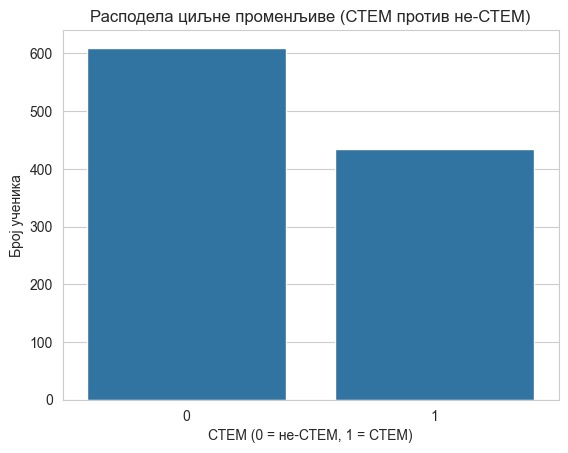

In [11]:
sns.countplot(x='STEM', data=df)
plt.xlabel('СТЕМ (0 = не-СТЕМ, 1 = СТЕМ)')
plt.ylabel('Број ученика')
plt.title('Расподела циљне променљиве (СТЕМ против не-СТЕМ)')
plt.show()

### 1.4.1. Искључивање колона за даље моделовање (описни / слободни текст)

Следеће колоне су **описног карактера** (слободан текст или сиров временски печат) и у овом облику нису погодне за директан унос у класичне предиктивне моделе без NLP или додатног кодирања. У наставку их избацујемо из матрице обележја `X`.

- `Timestamp`
- `Занимање твоје мајке:`, `Занимање твог оца:`
- `Зашто сте изабрали да упишите Гимназију?`, `Зашто сте изабрали да упишете овај смер?`

Циљна променљива остаје у `y` (колона `STEM` у `df`).


In [12]:
cols_to_drop = [
    'Timestamp',
    'Занимање твоје мајке:',
    'Занимање твог оца:',
    'Зашто сте изабрали да упишите Гимназију?',
    'Зашто сте изабрали да упишете овај смер?',
]
X = df.drop(columns=cols_to_drop)
y = df['STEM']

print('Колоне у X (укључујући STEM за EDA графике са hue):')
print(X.columns.tolist())

Колоне у X (укључујући STEM за EDA графике са hue):
['Пол:', 'Година рођења:', 'Похађам средњу школу:', 'Смер:', 'Разред:', 'Одрастао/ла сам у:', 'Основну школу сам завршио/ла у:', 'Стручна спрема твоје мајке:', 'Стручна спрема твог оца:', 'Колико има деце у твојој породици, рачунајући и тебе (упиши број):', 'Какав си био/ла ђак у основној школи?', 'Најомиљенији предмет:', 'Други омиљени предмет (омиљени предмет, мање омиљени од претходног):', 'Трећи омиљени предмет (омиљени предмет, мање омиљени од претходна два):', 'Тежак [Српски језик и књижевност]', 'Тежак [Енглески језик]', 'Тежак [2. страни језик]', 'Тежак [Историја]', 'Тежак [Географија]', 'Тежак [Биологија]', 'Тежак [Математика]', 'Тежак [Информатика]', 'Тежак [Физика]', 'Тежак [Хемија]', 'Тежак [Музичка култура]', 'Тежак [Ликовна култура]', 'Тежак [Физичко васпитање]', 'Тежак [Техника и технологија]', 'Корисан [Српски језик и књижевност]', 'Корисан [Енглески језик]', 'Корисан [2. страни језик]', 'Корисан [Историја]', 'Корисан 

In [ ]:
# Заједничке ознаке за STEM/не-STEM групу, коришћене у графицима и табелама у наставку
STEM_LABELS = {0: 'НЕ-СТЕМ', 1: 'СТЕМ', 0.0: 'НЕ-СТЕМ', 1.0: 'СТЕМ'}

# 2. Описна анализа

## 2.1. Анализа неких предмета који припадају СТЕМ областима

Поређење расподеле најчешћих оцена из математике, физике и (као референца) српског језика. Кутијасти дијаграм показује медијан, квартиле и изласке.

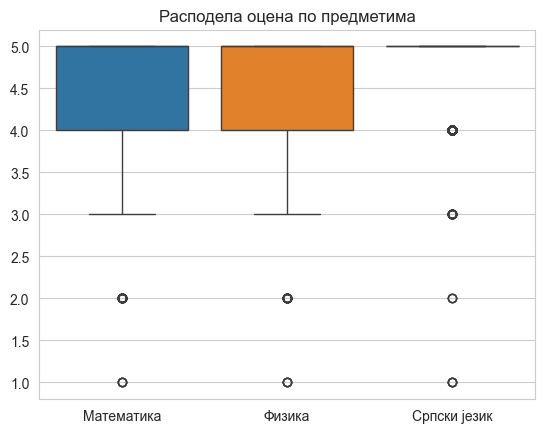

In [13]:
data = X[[
    'Најчешћа оцена [Математика]',
    'Најчешћа оцена [Физика]',
    'Најчешћа оцена [Српски језик и књижевност]',
]]

sns.boxplot(data=data)

plt.xticks(
    ticks=[0, 1, 2],
    labels=['Математика', 'Физика', 'Српски језик']
)

plt.title('Расподела оцена по предметима')
plt.show()

## 2.2. Анализа категоријских обележја

Фреквенције и графикони за изабране категоријске променљиве (нпр. пол, величина места одрастања).

In [14]:
X['Пол:'].value_counts()

Пол:
женски    715
мушки     329
Name: count, dtype: int64

In [15]:
X['Одрастао/ла сам у:'].value_counts()

Одрастао/ла сам у:
већем граду    712
селу           139
мањем граду     98
варошици        95
Name: count, dtype: int64

## 2.3. Однос категоријских обележја и СТЕМ опредељења

Упоредни приказ (hue = STEM) помаже да се види да ли се расподела категорије разликује између СТЕМ и не-СТЕМ групе.

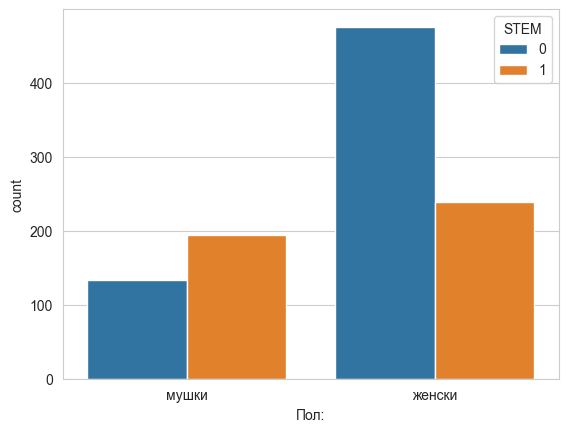

In [16]:
sns.countplot(x='Пол:', hue='STEM', data=X)
plt.show()

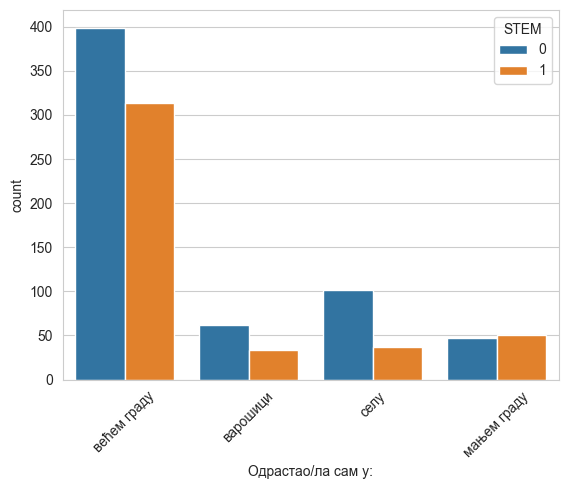

In [17]:
sns.countplot(x='Одрастао/ла сам у:', hue='STEM', data=X)
plt.xticks(rotation=45)
plt.show()

## 2.4. Стубичасти дијаграм (просеци)

Поређење **просечних** најчешћих оцена из математике, физике и српског језика између групе STEM и не-STEM (`groupby` + `plot(kind='bar')`).

In [ ]:
grade_cols_mean = [
    'Најчешћа оцена [Математика]',
    'Најчешћа оцена [Физика]',
    'Најчешћа оцена [Српски језик и књижевност]',
]
plot_df = X.groupby('STEM')[grade_cols_mean].mean()
plot_df.columns = ['Математика', 'Физика', 'Српски језик']
plot_df.index = [STEM_LABELS.get(k, k) for k in plot_df.index]
ax = plot_df.plot(kind='bar', rot=0, figsize=(8, 5), edgecolor='black')
plt.ylabel('Просечна најчешћа оцена')
plt.xlabel('Тип смера')
plt.title('Просек најчешћих оцена из математике, физике и српског језика по STEM опредељењу')
plt.legend(title='Предмет')
plt.tight_layout()
plt.show()

In [ ]:
def _likert_u_broj(x):
    """'1 - нимало' или већ int 1–5 → број за просек."""
    if pd.isna(x):
        return np.nan
    if isinstance(x, (int, np.integer)):
        return int(x)
    if isinstance(x, float) and x == int(x):
        return int(x)
    s = str(x).strip()
    if not s:
        return np.nan
    return int(s.split('-')[0].strip())

## 2.5. Корелациона матрица

### 2.5.1. Избор колона за ову матрицу

Користимо само: **STEM**, најчешће оцене из **математике**, **физике** и **информатике**, као и Ликерт процене **занимљивости** и **тежине** за **математику** и **физику** (списак је експлицитно у наредној ћелији).

Ликерт ставови се претварају у бројеве (види ћелију испод); затим се за изабране колоне рачуна **Спирманова (Spearman) корелација ранга**, а не Пирсонова: већина укључених променљивих је **ординална** (Ликерт скале 1–5, оцене), а Спирманова корелација претпоставља само монотону везу међу рангирањем вредности, без претпоставке да су размаци између категорија једнаки (што Пирсонова корелација имплицитно претпоставља). За STEM (бинарна) насупрот осталим, Спирманова корелација и даље даје валидну меру повезаности. Матрица је илустративна — за закључке о узрочности потребна је додатна анализа.

Питања са одговорима у облику *„1 - нимало“*, *„2 - мало“*, … мапирамо на цео број (1–5) преузимањем дела пре цртице (помоћу `_likert_u_broj` дефинисане изнад). То омогућава корелацију и топлотну мапу; **није** исто што и формално моделирање као континуиране променљиве, али је уобичајен корак у описној анализи.

In [ ]:
likert_cols = [
    col
    for col in X.columns
    if 'Процени' in col
    or col.startswith('Занимљив ')
    or col.startswith('Тежак ')
    or col.startswith('Корисан ')
]

for col in likert_cols:
    X[col] = X[col].apply(_likert_u_broj)

In [ ]:
selected_columns = [
    'STEM',
    'Најчешћа оцена [Математика]',
    'Најчешћа оцена [Физика]',
    'Најчешћа оцена [Информатика]',
    'Занимљив [Математика]',
    'Занимљив [Физика]',
    'Тежак [Математика]',
    'Тежак [Физика]',
]

corr = X[selected_columns].corr(method='spearman')

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.tight_layout()
plt.show()

# 3. Статистички тестови

У овом одељку формално тестирамо да ли постоји статистички значајна разлика или повезаност између STEM и не-STEM групе, за показатеље описане и приказане графички у наставку. Користе се два типа тестова:

- **t-тест за независне узорке** (Welch-ова варијанта, `equal_var=False`): за поређење просечне вредности нумеричке/ординалне променљиве (оцене, тежина, занимљивост, корисност) између две групе. Смер хипотезе (једнострано или двострано) наведен је уз сваки тест; тамо где се истовремено тестира више предмета за исту хипотезу, примењена је **Бонферонијева корекција** прага значајности.
- **χ² тест независности**: за две категоријске променљиве (нпр. пол × STEM, место одрастања × STEM) на контингенцијској табели, уз проверу претпоставке о минималним очекиваним фреквенцијама (све ≥ 5).

## 3.1. Оцене из STEM предмета: да ли STEM ученици имају боље оцене?

Поредимо **најчешће оцене** из типичних STEM предмета у основној школи (математика, физика, информатика, хемија, биологија — само колоне које постоје у `X`) између група **STEM** и **не-STEM**. Приказујемо **просек** по групи и **Welch t-тест** (`equal_var=False`) са `alternative='greater'`: хипотеза да је просек у STEM групи **већи** од не-STEM.

Пошто се овде спроводи **пет** t-тестова над истом врстом хипотезе (различити предмети), примењена је **Бонферонијева корекција** (прилагођени праг значајности α/5) како би се контролисала вероватноћа лажно позитивног резултата услед вишеструког тестирања. Резултат: сви тестови остају статистички значајни и након корекције.

Ово поређење је **описно** у смислу групе које се пореде — не значи да је избор смера *узрок* разлике у оценама.

In [ ]:
STEM_PREDMET_OCENE = [
    'Најчешћа оцена [Математика]',
    'Најчешћа оцена [Физика]',
    'Најчешћа оцена [Информатика]',
    'Најчешћа оцена [Хемија]',
    'Најчешћа оцена [Биологија]',
]
stem_grade_cols = [c for c in STEM_PREDMET_OCENE if c in X.columns]

means_stem_pred = (
    X.groupby('STEM')[stem_grade_cols]
    .mean()
    .round(3)
    .rename(index=lambda k: STEM_LABELS.get(k, k))
)
means_stem_pred.columns = [
    c.replace('Најчешћа оцена [', '').replace(']', '') for c in means_stem_pred.columns
]
print('Просечна најчешћа оцена по групи (STEM предмети):')
print(means_stem_pred)

plot_stem = means_stem_pred.copy()
ax = plot_stem.plot(kind='bar', rot=0, figsize=(9, 5), edgecolor='black')
plt.ylabel('Просечна најчешћа оцена')
plt.xlabel('Група')
plt.title('STEM предмети: просек најчешће оцене — STEM vs не-STEM')
plt.legend(title='Предмет', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

ALPHA = 0.05
m = len(stem_grade_cols)
alpha_bonferroni = ALPHA / m

print("Welch t-тест, једнострано STEM > не-STEM (scipy: alternative='greater'):")
print(f"Бонферонијева корекција за {m} тестова: прилагођени праг значајности = {ALPHA}/{m} = {alpha_bonferroni:.4f}\n")
for col in stem_grade_cols:
    a = pd.to_numeric(X.loc[X['STEM'] == 1, col], errors='coerce').dropna()
    b = pd.to_numeric(X.loc[X['STEM'] == 0, col], errors='coerce').dropna()
    res = ttest_ind(a, b, equal_var=False, alternative='greater')
    predmet = col.replace('Најчешћа оцена [', '').replace(']', '')
    znacajno_bonferroni = 'да' if res.pvalue < alpha_bonferroni else 'не'
    print(
        f"  {predmet}: t={res.statistic:.3f}, p={res.pvalue:.5f} "
        f"(n_stem={len(a)}, n_non={len(b)}, mean_stem={a.mean():.3f}, mean_non={b.mean():.3f}) "
        f"-> значајно након Бонферонијеве корекције: {znacajno_bonferroni}"
    )


## 3.2. Да ли STEM ученици доживљавају STEM предмете као лакше?

За **математику** и **физику** у основној школи питамо колико је предмет био **тежак** (Ликерт: већи број = већа пријављена тежина, типично 1–5). **Нижи просек** у групи STEM у односу на не-STEM значи да те предмете **просечно доживљавају као лакше** (мање тешке).

Хипотеза се тестира Welch t-тестом, једнострано (STEM < не-STEM), уз **Бонферонијеву корекцију** за 2 теста (математика, физика) — прилагођени праг значајности α/2.

In [ ]:
tez_cols = ['Тежак [Математика]', 'Тежак [Физика]']
tmp = X[['STEM']].copy()
for c in tez_cols:
    tmp[c] = X[c].map(_likert_u_broj)

means_tez = tmp.groupby('STEM')[tez_cols].mean().round(3)
means_tez.columns = ['Математика', 'Физика']
means_tez.index = [STEM_LABELS.get(i, i) for i in means_tez.index]

print('Просечна пријављена тежина (већи број = теже; нижи просек = лакше):')
print(means_tez)

ax = means_tez.plot(kind='bar', rot=0, figsize=(7, 4.5), edgecolor='black')
plt.ylabel('Просек скале „тежина предмета“')
plt.xlabel('Група')
plt.title('Перципирана тежина: математика и физика (STEM vs не-STEM)')
plt.axhline(y=3, color='grey', linestyle='--', linewidth=0.8, label='Средина скале (3)')
plt.legend(title='Предмет / референца')
plt.tight_layout()
plt.show()

ALPHA = 0.05
m = len(tez_cols)
alpha_bonferroni = ALPHA / m

print("Welch t-тест, једнострано STEM < не-STEM (scipy: alternative='less'):")
print(f"Бонферонијева корекција за {m} теста: прилагођени праг значајности = {ALPHA}/{m} = {alpha_bonferroni:.4f}\n")
for col in tez_cols:
    a = tmp.loc[tmp['STEM'] == 1, col].dropna()
    b = tmp.loc[tmp['STEM'] == 0, col].dropna()
    res = ttest_ind(a, b, equal_var=False, alternative='less')
    predmet = col.replace('Тежак [', '').replace(']', '')
    znacajno_bonferroni = 'да' if res.pvalue < alpha_bonferroni else 'не'
    print(
        f"  {predmet}: t={res.statistic:.3f}, p={res.pvalue:.6f} "
        f"(n_stem={len(a)}, n_non={len(b)}, mean_stem={a.mean():.3f}, mean_non={b.mean():.3f}) "
        f"-> значајно након Бонферонијеве корекције: {znacajno_bonferroni}"
    )

## 3.3. Да ли су им занимљивији STEM предмети (математика и физика)?

За **математику** и **физику** у основној школи питамо колико је предмет био **занимљив** (Ликерт, типично 1–5: **већи број = већа пријављена занимљивост**). **Виши просек** у групи STEM у односу на не-STEM значи да те предмете **просечно доживљавају као занимљивије**.

Хипотеза се тестира Welch t-тестом (двострано), уз **Бонферонијеву корекцију** за 2 теста (математика, физика) — прилагођени праг значајности α/2.

In [ ]:
zan_cols = ['Занимљив [Математика]', 'Занимљив [Физика]']
tmp_z = X[['STEM']].copy()
for c in zan_cols:
    tmp_z[c] = X[c].map(_likert_u_broj)

means_zan = tmp_z.groupby('STEM')[zan_cols].mean().round(3)
means_zan.columns = ['Математика', 'Физика']
means_zan.index = [STEM_LABELS.get(i, i) for i in means_zan.index]

print('Просечна пријављена занимљивост (већи број = занимљивије; виши просек = занимљивије):')
print(means_zan)

ax = means_zan.plot(kind='bar', rot=0, figsize=(7, 4.5), edgecolor='black')
plt.ylabel('Просек скале „занимљивост предмета“')
plt.xlabel('Група')
plt.title('Занимљивост: математика и физика (STEM vs не-STEM)')
plt.axhline(y=3, color='grey', linestyle='--', linewidth=0.8, label='Средина скале (3)')
plt.legend(title='Предмет / референца')
plt.tight_layout()
plt.show()

ALPHA = 0.05
m = len(zan_cols)
alpha_bonferroni = ALPHA / m

print("Welch t-тест, двострано (STEM vs не-STEM):")
print(f"Бонферонијева корекција за {m} теста: прилагођени праг значајности = {ALPHA}/{m} = {alpha_bonferroni:.4f}\n")
for col in zan_cols:
    a = tmp_z.loc[tmp_z['STEM'] == 1, col].dropna()
    b = tmp_z.loc[tmp_z['STEM'] == 0, col].dropna()
    res = ttest_ind(a, b, equal_var=False)
    predmet = col.replace('Занимљив [', '').replace(']', '')
    znacajno_bonferroni = 'да' if res.pvalue < alpha_bonferroni else 'не'
    print(
        f"  {predmet}: t={res.statistic:.3f}, p={res.pvalue:.10f} "
        f"(n_stem={len(a)}, n_non={len(b)}, mean_stem={a.mean():.3f}, mean_non={b.mean():.3f}) "
        f"-> значајно након Бонферонијеве корекције: {znacajno_bonferroni}"
    )

## 3.4. Да ли су им кориснији STEM предмети (математика и физика)?

За **математику** и **физику** у основној школи питамо колико је предмет био **користан** (Ликерт, типично 1–5: **већи број = већа пријављена корисност**). **Виши просек** у групи STEM у односу на не-STEM значи да **у просеку приписују већу корисност** тим предметима на скали.

Хипотеза се тестира Welch t-тестом, једнострано (STEM > не-STEM), уз **Бонферонијеву корекцију** за 2 теста (математика, физика) — прилагођени праг значајности α/2.

In [ ]:
kor_cols = ['Корисан [Математика]', 'Корисан [Физика]']
tmp_k = X[['STEM']].copy()
for c in kor_cols:
    tmp_k[c] = X[c].map(_likert_u_broj)

means_kor = tmp_k.groupby('STEM')[kor_cols].mean().round(3)
means_kor.columns = ['Математика', 'Физика']
means_kor.index = [STEM_LABELS.get(i, i) for i in means_kor.index]

print('Просечна пријављена корисност (већи број = корисније; виши просек = корисније):')
print(means_kor)

ax = means_kor.plot(kind='bar', rot=0, figsize=(7, 4.5), edgecolor='black')
plt.ylabel('Просек скале „корисност предмета“')
plt.xlabel('Група')
plt.title('Корисност: математика и физика (STEM vs не-STEM)')
plt.axhline(y=3, color='grey', linestyle='--', linewidth=0.8, label='Средина скале (3)')
plt.legend(title='Предмет / референца')
plt.tight_layout()
plt.show()

ALPHA = 0.05
m = len(kor_cols)
alpha_bonferroni = ALPHA / m

print("Welch t-тест, једнострано STEM > не-STEM (scipy: alternative='greater'):")
print(f"Бонферонијева корекција за {m} теста: прилагођени праг значајности = {ALPHA}/{m} = {alpha_bonferroni:.4f}\n")
for col in kor_cols:
    a = tmp_k.loc[tmp_k['STEM'] == 1, col].dropna()
    b = tmp_k.loc[tmp_k['STEM'] == 0, col].dropna()
    res = ttest_ind(a, b, equal_var=False, alternative='greater')
    predmet = col.replace('Корисан [', '').replace(']', '')
    znacajno_bonferroni = 'да' if res.pvalue < alpha_bonferroni else 'не'
    print(
        f"  {predmet}: t={res.statistic:.3f}, p={res.pvalue:.10f} "
        f"(n_stem={len(a)}, n_non={len(b)}, mean_stem={a.mean():.3f}, mean_non={b.mean():.3f}) "
        f"-> значајно након Бонферонијеве корекције: {znacajno_bonferroni}"
    )

## 3.5. $\chi^2$ тест независности (пол × STEM)

Градимо контингенцијску табелу и примењујемо `chi2_contingency` из SciPy.

In [ ]:
ct = pd.crosstab(X['Пол:'], X['STEM'], margins=True)
print(ct)

ct_core = pd.crosstab(X['Пол:'], X['STEM'])
chi2, p, dof, expected = chi2_contingency(ct_core)
print(f'χ² = {chi2:.4f}, p-value = {p:.6f}, степени слободе = {dof}')

print('\nОчекиване фреквенције (претпоставка χ² теста: све ≥ 5):')
expected_df = pd.DataFrame(expected, index=ct_core.index, columns=ct_core.columns).round(2)
print(expected_df)
print(f"\nНајмања очекивана фреквенција: {expected.min():.2f} "
      f"-> претпоставка {'испуњена' if expected.min() >= 5 else 'НИЈЕ испуњена'}")

## 3.6. $\chi^2$ тест независности (Одрастао/ла сам у: × STEM)

Иста логика, за место одрастања (град/варошица/село) наспрам STEM опредељења.

In [ ]:
ct_odrastao = pd.crosstab(X['Одрастао/ла сам у:'], X['STEM'], margins=True)
print(ct_odrastao)

ct_odrastao_core = pd.crosstab(X['Одрастао/ла сам у:'], X['STEM'])
chi2, p, dof, expected = chi2_contingency(ct_odrastao_core)
print(f'χ² = {chi2:.4f}, p-value = {p:.6f}, степени слободе = {dof}')

print('\nОчекиване фреквенције (претпоставка χ² теста: све ≥ 5):')
expected_df = pd.DataFrame(expected, index=ct_odrastao_core.index, columns=ct_odrastao_core.columns).round(2)
print(expected_df)
print(f"\nНајмања очекивана фреквенција: {expected.min():.2f} "
      f"-> претпоставка {'испуњена' if expected.min() >= 5 else 'НИЈЕ испуњена'}")

# 4. Предобрада података за моделовање

Пре него што подаци буду коришћени за тренирање предиктивних модела, потребно је спровести низ корака предобраде: уклањање непотребних/ризичних колона, обраду недостајућих вредности, детекцију дупликата и аномалија, енкодирање категоријских и скалирање нумеричких обележја, поделу на тренинг/тест скуп и селекцију обележја.

## 4.1. Уклањање непотребних колона

Уклањамо колоне које нису погодне или безбедне за моделовање (нпр. изворна колона `Смер:` из које је изведена циљна променљива `STEM`, слободнотекстуалне колоне итд.).

## 4.2. Обрада недостајућих вредности

Проверавамо да ли је, након уклањања колона у одељку 4.1, потребна додатна обрада недостајућих вредности.

## 4.3. Детекција дупликата

Проверавамо да ли скуп података садржи потпуно идентичне (дуплиране) редове.

## 4.4. Детекција аномалија

Детектујемо изразите аутлајере/аномалије у подацима, нпр. помоћу Isolation Forest алгоритма.

## 4.5. Енкодирање категоријских променљивих

Категоријске (текстуалне) променљиве трансформишемо у нумерички облик погодан за моделе машинског учења.

## 4.6. Скалирање нумеричких обележја

Нумеричка обележја скалирамо на заједнички опсег/распон, што је важно за одређене типове модела.

## 4.7. Подела скупа података

Скуп података делимо на тренинг и тест подскуп (stratified train-test split), уз стратификацију по циљној променљивој `STEM` како би удео STEM/не-STEM ученика остао приближно исти у оба подскупа.

## 4.8. Селекција обележја

Бирамо најрелевантнија обележја за коначни модел.